Q 1(a) 
Column Names: ['Study_Hours', 'Attendance_Percent', 'Practice_Tests', 'Sleep_Hours', 'Assignments_Completed', 'Screen_Time_Hours', 'Final_Score']
Number of Samples: 500
Number of Features: 6
Target Variable: Final_Score


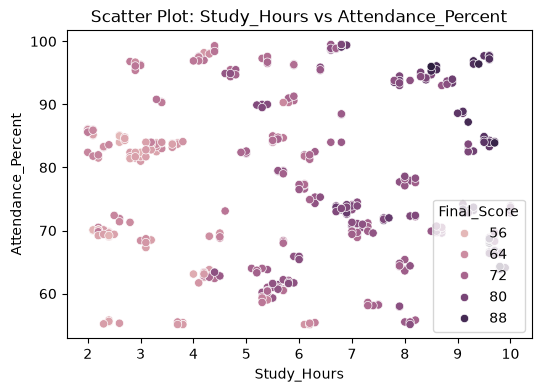


 Q1(b) Correlation Matrix
                       Study_Hours  Attendance_Percent  Practice_Tests  \
Study_Hours               1.000000            0.026510        0.886156   
Attendance_Percent        0.026510            1.000000        0.043830   
Practice_Tests            0.886156            0.043830        1.000000   
Sleep_Hours               0.147746           -0.128525        0.149766   
Assignments_Completed    -0.027034           -0.036811        0.044144   
Screen_Time_Hours        -0.155519            0.087211       -0.105349   
Final_Score               0.878533            0.154457        0.885623   

                       Sleep_Hours  Assignments_Completed  Screen_Time_Hours  \
Study_Hours               0.147746              -0.027034          -0.155519   
Attendance_Percent       -0.128525              -0.036811           0.087211   
Practice_Tests            0.149766               0.044144          -0.105349   
Sleep_Hours               1.000000               0.161441   

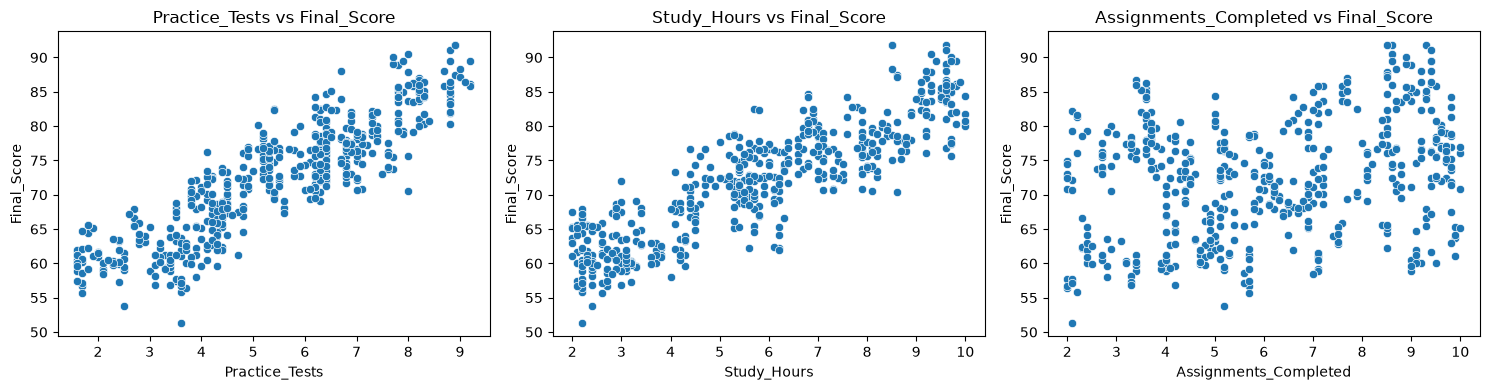

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df = pd.read_csv("Student_Performance_Prediction.csv")

print("Q 1(a) ")
print("Column Names:", df.columns.tolist())
print("Number of Samples:", df.shape[0])
print("Number of Features:", df.shape[1] - 1)
target_variable = "Final_Score"
print("Target Variable:", target_variable)

num_features = df.select_dtypes(include=[np.number]).columns.tolist()
if len(num_features) >= 2:
  plt.figure(figsize=(6, 4))
  sns.scatterplot(x=df[num_features[0]], y=df[num_features[1]], hue=df[target_variable])
  plt.title(f"Scatter Plot: {num_features[0]} vs {num_features[1]}")
  plt.xlabel(num_features[0])
  plt.ylabel(num_features[1])
  plt.show()

# (b) Pearson correlation matrix between numerical features
corr_matrix = df[num_features].corr(method="pearson")
print("\n Q1(b) Correlation Matrix")
print(corr_matrix)

# (c) Pearson correlation coefficient between each numerical feature and the target variable
target_corr = corr_matrix[target_variable].drop(target_variable)
print("\n--- Q1(c) Correlation")
print(target_corr)

# (d) Rank features according to absolute strength of correlation with target
ranked_features = target_corr.abs().sort_values(ascending=False)
print("\n Q1(d)")
print(ranked_features)
most_influential = ranked_features.index[0]
print(f"Most Influential Feature: {most_influential}")

# (e) Visualise relationship between target and top three features
top_3_features = ranked_features.head(3).index.tolist()
print(f"\n Q1(e) Top 3 Features: {top_3_features}")
plt.figure(figsize=(15, 4))
for i, feat in enumerate(top_3_features, 1):
  plt.subplot(1, 3, i)
  sns.scatterplot(x=df[feat], y=df[target_variable])
  plt.title(f"{feat} vs {target_variable}")
plt.tight_layout()
plt.show()

In [5]:
threshold_collinear = 0.70
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
  for j in range(i):
    if (abs(corr_matrix.iloc[i, j]) >= threshold_collinear
        and corr_matrix.columns[i] != target_variable and corr_matrix.columns[j] != target_variable):
      high_corr_pairs.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j]))

print(" Q2(a) Highly Correlated pairs/")
for pair in high_corr_pairs:
  print(f"{pair[0]} & {pair[1]}: r = {pair[2]:.2f}")

threshold_target = 0.40
strong_target_features = target_corr[target_corr.abs() >= threshold_target].index.tolist()
print("\nQ2(b)" )
print(strong_target_features)

features_to_drop = set()
for feat1, feat2, _ in high_corr_pairs:
  corr1 = abs(target_corr[feat1])
  corr2 = abs(target_corr[feat2])
  if corr1 >= corr2:
    features_to_drop.add(feat2)
  else:
    features_to_drop.add(feat1)

selected_features = [f for f in strong_target_features if f not in features_to_drop]
modified_cols = selected_features + [target_variable]
modified_df = df[modified_cols]

# Save modified dataset
modified_df.to_csv("modified_Student_Performance.csv", index=False)
print(    "\nQ2(d)""\nModified dataset saved  with"f" features: {selected_features}")

 Q2(a) Highly Correlated pairs/
Practice_Tests & Study_Hours: r = 0.89

Q2(b)
['Study_Hours', 'Practice_Tests']

Q2(d)
Modified dataset saved  with features: ['Practice_Tests']


 Original Dataset Linear Regression Results 
MAE: 1.8174 | MSE: 5.3229 | RMSE: 2.3071 | R2: 0.9248
Regression Equation:
Y = 41.5999 + 1.7590 * Study_Hours + 0.0929 * Attendance_Percent + 1.8213 * Practice_Tests + -0.0897 * Sleep_Hours + 1.1365 * Assignments_Completed + -0.6162 * Screen_Time_Hours



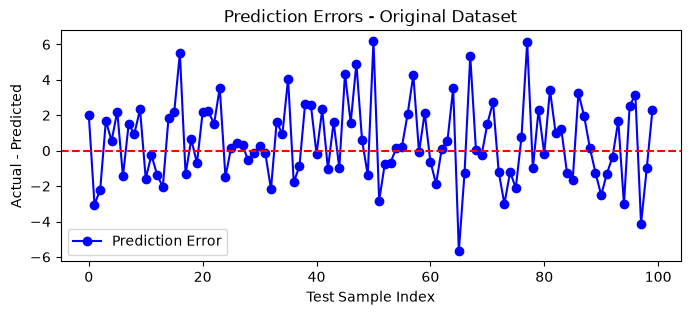

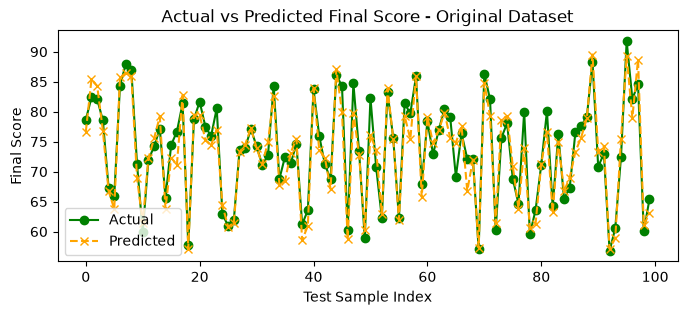

 Modified Dataset Linear Regression Results 
MAE: 3.4250 | MSE: 17.6615 | RMSE: 4.2026 | R2: 0.7506
Regression Equation:
Y = 51.4839 + 3.8729 * Practice_Tests



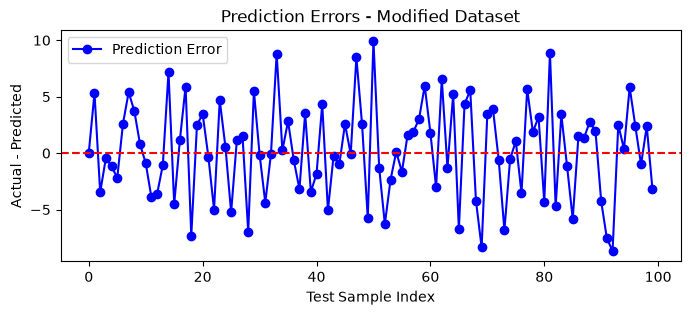

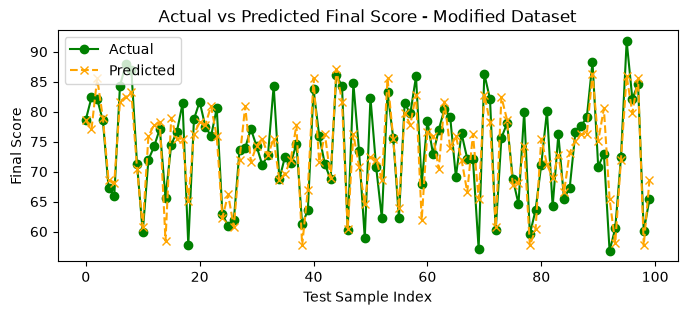

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split


def evaluate_linear_regression(X, y, dataset_name):
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

  model = LinearRegression()
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)

  # (a) Metrics
  mae = mean_absolute_error(y_test, y_pred)
  mse = mean_squared_error(y_test, y_pred)
  rmse = np.sqrt(mse)
  r2 = r2_score(y_test, y_pred)

  print(f" {dataset_name} Linear Regression Results ")
  print(f"MAE: {mae:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | R2: {r2:.4f}")

  # (b) Regression Equation
  coefs = [
      f"{c:.4f} * {col}" for c, col in zip(model.coef_, X.columns)
  ]  # noqa
  equation = f"Y = {model.intercept_:.4f} + " + " + ".join(coefs)
  print(f"Regression Equation:\n{equation}\n")

  # (c) Prediction Error Plot
  errors = y_test.values - y_pred
  plt.figure(figsize=(8, 3))
  plt.plot(
      range(len(errors)),
      errors,
      marker="o",
      linestyle="-",
      color="b",
      label="Prediction Error",
  )
  plt.axhline(0, color="r", linestyle="--")
  plt.title(f"Prediction Errors - {dataset_name}")
  plt.xlabel("Test Sample Index")
  plt.ylabel("Actual - Predicted")
  plt.legend()
  plt.show()

  # (d) Actual vs Predicted Plot
  plt.figure(figsize=(8, 3))
  plt.plot(
      range(len(y_test)),
      y_test.values,
      label="Actual",
      marker="o",
      color="green",
  )
  plt.plot(
      range(len(y_test)),
      y_pred,
      label="Predicted",
      marker="x",
      color="orange",
      linestyle="--",
  )
  plt.title(f"Actual vs Predicted Final Score - {dataset_name}")
  plt.xlabel("Test Sample Index")
  plt.ylabel("Final Score")
  plt.legend()
  plt.show()


# Run for Original Dataset
X_orig = df.drop(columns=[target_variable])
y_orig = df[target_variable]
evaluate_linear_regression(X_orig, y_orig, "Original Dataset")

# Run for Modified Dataset
X_mod = modified_df.drop(columns=[target_variable])
y_mod = modified_df[target_variable]
evaluate_linear_regression(X_mod, y_mod, "Modified Dataset")


Q4(b) Polynomial Regression 
Degree 2 -> Train MSE: 4.2437 | Test MSE: 5.5078 | Train R2: 0.9422 | Test R2: 0.9222
Degree 3 -> Train MSE: 3.8324 | Test MSE: 5.7890 | Train R2: 0.9478 | Test R2: 0.9183
Degree 4 -> Train MSE: 3.8325 | Test MSE: 6.1061 | Train R2: 0.9478 | Test R2: 0.9138


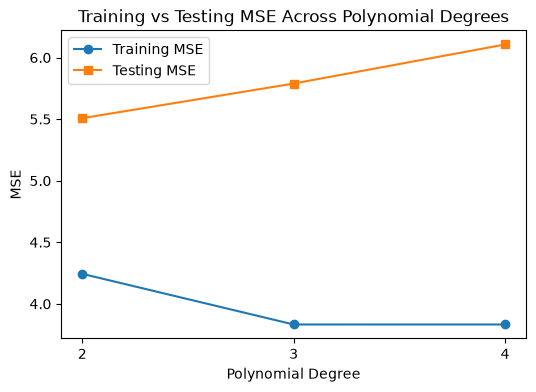

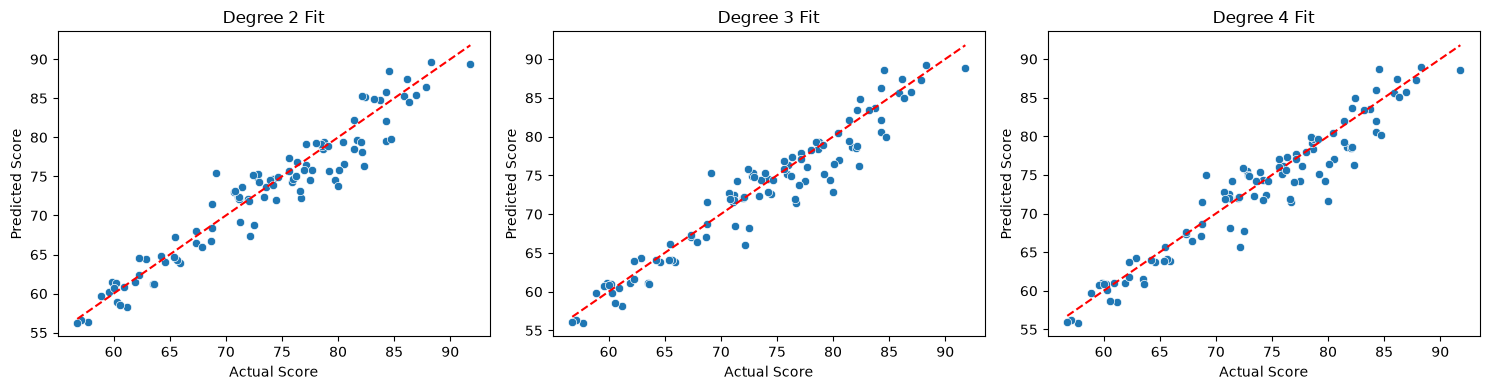

In [14]:
from sklearn.preprocessing import PolynomialFeatures

X = df.drop(columns=[target_variable])
y = df[target_variable]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

degrees = [2, 3, 4]
train_mse_list, test_mse_list = [], []
train_r2_list, test_r2_list = [], []

print("Q4(b) Polynomial Regression ")
for deg in degrees:
  poly = PolynomialFeatures(degree=deg, include_bias=False)
  X_train_poly = poly.fit_transform(X_train)
  X_test_poly = poly.transform(X_test)

  poly_model = LinearRegression()
  poly_model.fit(X_train_poly, y_train)

  y_train_pred = poly_model.predict(X_train_poly)
  y_test_pred = poly_model.predict(X_test_poly)

  tr_mse = mean_squared_error(y_train, y_train_pred)
  te_mse = mean_squared_error(y_test, y_test_pred)
  tr_r2 = r2_score(y_train, y_train_pred)
  te_r2 = r2_score(y_test, y_test_pred)

  train_mse_list.append(tr_mse)
  test_mse_list.append(te_mse)
  train_r2_list.append(tr_r2)
  test_r2_list.append(te_r2)

  print(
      f"Degree {deg} -> Train MSE: {tr_mse:.4f} | Test MSE: {te_mse:.4f} |"
      f" Train R2: {tr_r2:.4f} | Test R2: {te_r2:.4f}"
  )

# (c) Plot Training MSE and Testing MSE vs Polynomial Degree
plt.figure(figsize=(6, 4))
plt.plot(degrees, train_mse_list, marker="o", label="Training MSE")
plt.plot(degrees, test_mse_list, marker="s", label="Testing MSE")
plt.title("Training vs Testing MSE Across Polynomial Degrees")
plt.xlabel("Polynomial Degree")
plt.ylabel("MSE")
plt.xticks(degrees)
plt.legend()
plt.show()

# (d) Scatter plots of Actual vs Predicted for degrees 2, 3, 4
plt.figure(figsize=(15, 4))
for i, deg in enumerate(degrees, 1):
  poly = PolynomialFeatures(degree=deg, include_bias=False)
  X_test_poly = poly.fit_transform(X_test) 
  poly_model = LinearRegression()
  poly_model.fit(poly.fit_transform(X_train), y_train)
  y_test_pred = poly_model.predict(X_test_poly)

  plt.subplot(1, 3, i)
  sns.scatterplot(x=y_test, y=y_test_pred)
  plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--"  )  
  plt.title(f"Degree {deg} Fit")
  plt.xlabel("Actual Score")
  plt.ylabel("Predicted Score")
plt.tight_layout()
plt.show()

In [16]:
# (a) Create new feature
df_home = df.copy()
df_home["Academic_Activity"] = (df_home["Practice_Tests"] + df_home["Assignments_Completed"])

# (b) Calculate Pearson correlation coefficient with Final Score
new_feature_corr = df_home[["Practice_Tests", "Assignments_Completed", "Academic_Activity", "Final_Score"]].corr(method="pearson")["Final_Score"]
print("Home Assignment 1(b) Correlations")
print(new_feature_corr)

# (c) Save feature engineered dataset
df_home.to_csv("feature_engineered_Student_Performance.csv", index=False)
print("\nDataset saved  as" " 'feature_engineered_Student_Performance.csv'.")

Home Assignment 1(b) Correlations
Practice_Tests           0.885623
Assignments_Completed    0.277262
Academic_Activity        0.761279
Final_Score              1.000000
Name: Final_Score, dtype: float64

Dataset saved  as 'feature_engineered_Student_Performance.csv'.


In [19]:
# (a) & (b) Split and train Polynomial Regression (Degrees 2 and 3)
X_fe = df_home.drop(columns=["Final_Score"])
y_fe = df_home["Final_Score"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X_fe, y_fe, test_size=0.2, random_state=42
)

comparison_results = []
for deg in [2, 3]:
  poly = PolynomialFeatures(degree=deg, include_bias=False)
  X_tr_p = poly.fit_transform(X_tr)
  X_te_p = poly.transform(X_te)

  model = LinearRegression()
  model.fit(X_tr_p, y_tr)

  tr_pred = model.predict(X_tr_p)
  te_pred = model.predict(X_te_p)

  comparison_results.append({
      "Degree": deg,
      "Train MSE": mean_squared_error(y_tr, tr_pred),
      "Test MSE": mean_squared_error(y_te, te_pred),
      "Train R2": r2_score(y_tr, tr_pred),
      "Test R2": r2_score(y_te, te_pred),  })

# (c) Comparison Table
comparison_df = pd.DataFrame(comparison_results)
print("\n--- Home Assignment 2(c) Comparison Table ---")
print(comparison_df)

# (g) Predict Final Score for three new hypothetical students using the selected model (e.g., Degree 2)
best_poly = PolynomialFeatures(degree=2, include_bias=False)
best_model = LinearRegression()
best_model.fit(best_poly.fit_transform(X_tr), y_tr)

new_students_data = pd.DataFrame({col: [5, 3, 8] for col in X_fe.columns} )

new_preds = best_model.predict(best_poly.transform(new_students_data))

new_students_data["Predicted_Final_Score"] = new_preds
print("\nHome Assignment-2(g) New Students ")
print(new_students_data)


--- Home Assignment 2(c) Comparison Table ---
   Degree  Train MSE  Test MSE  Train R2   Test R2
0       2   4.243676  5.507801  0.942241  0.922232
1       3   3.780590  5.673110  0.948544  0.919898

Home Assignment-2(g) New Students 
   Study_Hours  Attendance_Percent  Practice_Tests  Sleep_Hours  \
0            5                   5               5            5   
1            3                   3               3            3   
2            8                   8               8            8   

   Assignments_Completed  Screen_Time_Hours  Academic_Activity  \
0                      5                  5                  5   
1                      3                  3                  3   
2                      8                  8                  8   

   Predicted_Final_Score  
0              60.890562  
1              54.107579  
2              74.102616  
